In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import metrics
from scipy.stats import shapiro
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson

In [2]:
path = 'data/train.csv'
df=pd.read_csv(path)
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


In [4]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [5]:
house_price = pd.read_csv(path, usecols=['LotArea','TotalBsmtSF', 'MSSubClass', 'SalePrice'])

In [7]:
house_price.info()
house_price.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   MSSubClass   1460 non-null   int64
 1   LotArea      1460 non-null   int64
 2   TotalBsmtSF  1460 non-null   int64
 3   SalePrice    1460 non-null   int64
dtypes: int64(4)
memory usage: 45.8 KB


,MSSubClass,LotArea,TotalBsmtSF,SalePrice
count,1460.000000,1460.000000,1460.000000,1460.000000
mean,56.897260,10516.828082,1057.429452,180921.195890
std,42.300571,9981.264932,438.705324,79442.502883
min,20.000000,1300.000000,0.000000,34900.000000
25%,20.000000,7553.500000,795.750000,129975.000000
50%,50.000000,9478.500000,991.500000,163000.000000
75%,70.000000,11601.500000,1298.250000,214000.000000
max,190.000000,215245.000000,6110.000000,755000.000000


In [10]:
# Cek missing Value dan duplikat

house_price.isna().sum()

duplicate = house_price[house_price.duplicated()]
duplicate

,MSSubClass,LotArea,TotalBsmtSF,SalePrice
193,160,2522,970,130000


In [ ]:
# hapus duplikat
house_price.drop_duplicates(inplace=True)

In [12]:
# Cek shapenya kolom baris
house_price.shape

(1459, 4)

<Axes: xlabel='SalePrice', ylabel='Count'>

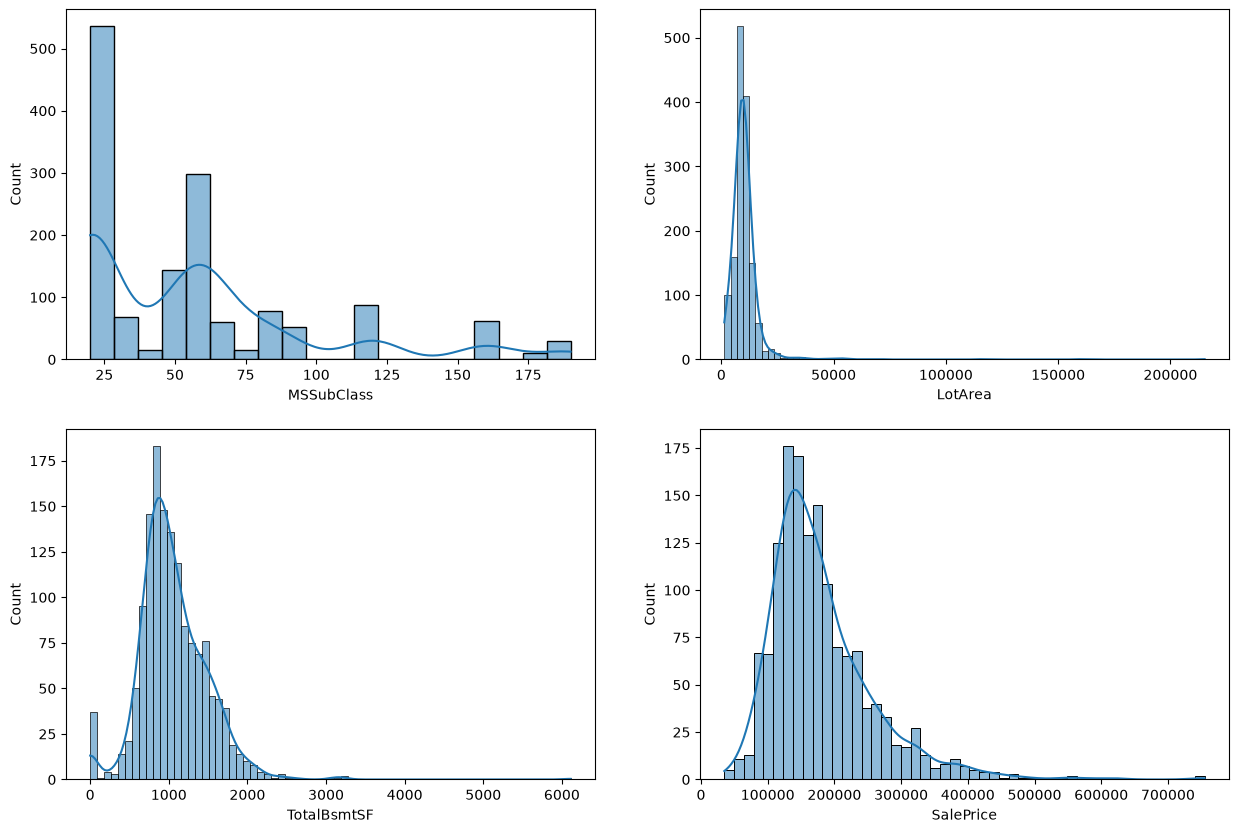

In [ ]:
# Uji Histogram
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(house_price["MSSubClass"], kde=True, ax=axes[0,0])
sns.histplot(house_price["LotArea"], kde=True, ax=axes[0,1])
sns.histplot(house_price["TotalBsmtSF"], kde=True, ax=axes[1,0])
sns.histplot(house_price["SalePrice"], kde=True, ax=axes[1,1])

<Axes: xlabel='SalePrice'>

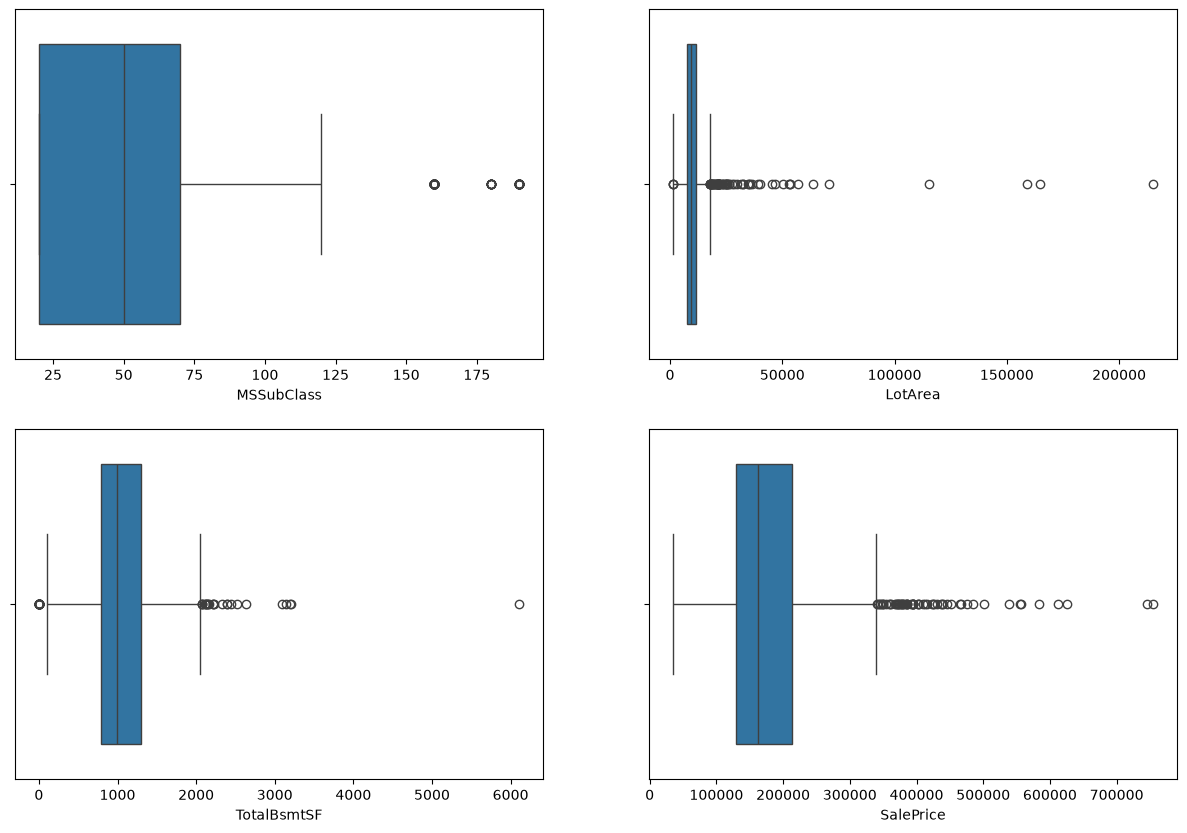

In [ ]:
# Uji Boxplot
fig, axes = plt.subplots(2,2, figsize=(15, 10))
sns.boxplot(x=house_price['MSSubClass'], ax= axes[0,0])
sns.boxplot(x=house_price['LotArea'], ax= axes[0,1])
sns.boxplot(x=house_price['TotalBsmtSF'], ax= axes[1,0])
sns.boxplot(x=house_price['SalePrice'], ax= axes[1,1])

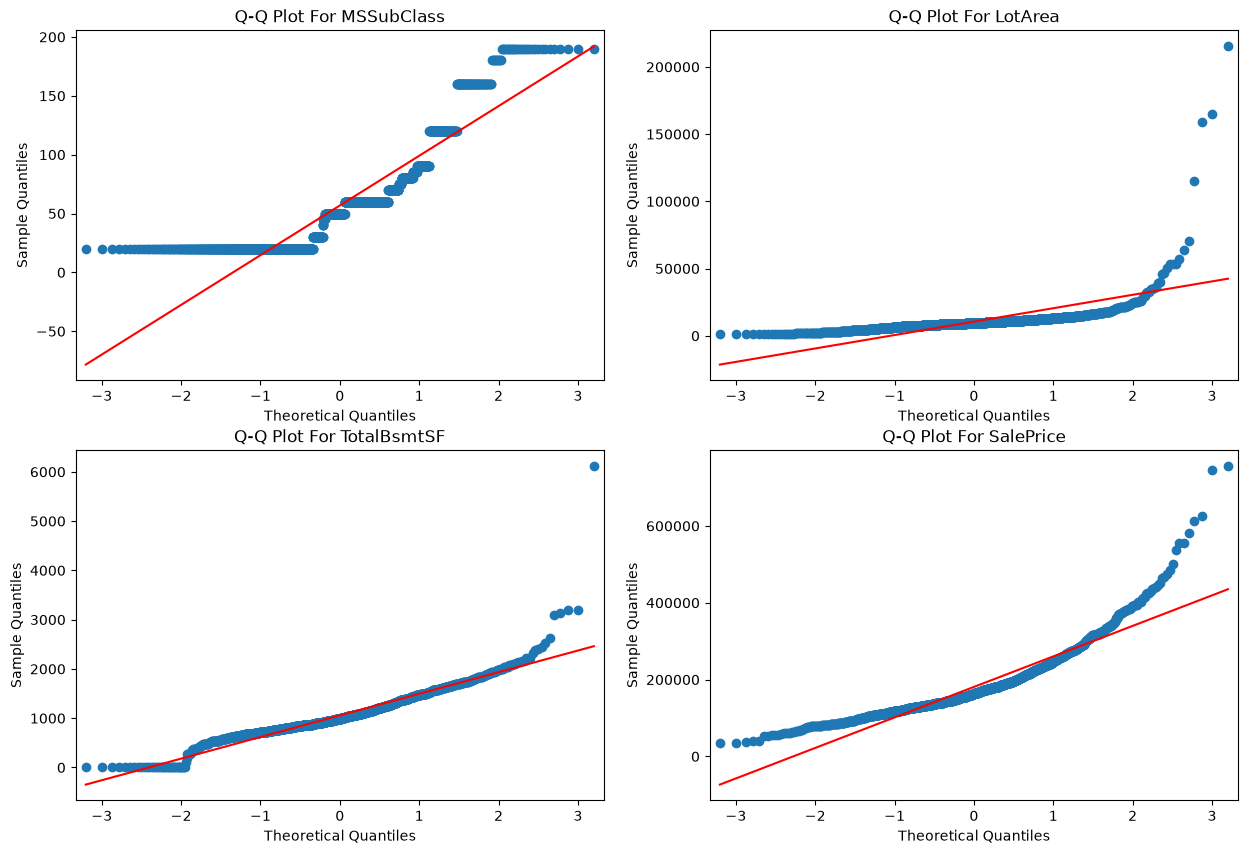

In [18]:
# Uji Qplot

fig, axes = plt.subplots(2,2, figsize=(15,10))

sm.graphics.qqplot(house_price['MSSubClass'].dropna(), line='s', ax=axes[0,0])
axes[0,0].title.set_text("Q-Q Plot For MSSubClass")

sm.graphics.qqplot(house_price['LotArea'].dropna(), line='s', ax=axes[0,1])
axes[0,1].title.set_text("Q-Q Plot For LotArea")

sm.graphics.qqplot(house_price['TotalBsmtSF'].dropna(), line='s', ax=axes[1,0])
axes[1,0].title.set_text("Q-Q Plot For TotalBsmtSF")

sm.graphics.qqplot(house_price['SalePrice'].dropna(), line='s', ax=axes[1,1])
axes[1,1].title.set_text("Q-Q Plot For SalePrice")


In [19]:
# Uji Shapiro

column = house_price.columns

for i in column:
    stat, p = shapiro(house_price[i])
    print("Statistics = %.3f, p=%.3f"% (stat, p))
    alpha = 0.05
    if p > alpha:
        print("Gagal tolak H_0, {} Berdistribusi Normal".format(i))
    else:
        print("Total H_0, {} tidak berdistribusi Normal".format(i))

Statistics = 0.804, p=0.000
Total H_0, MSSubClass tidak berdistribusi Normal
Statistics = 0.351, p=0.000
Total H_0, LotArea tidak berdistribusi Normal
Statistics = 0.917, p=0.000
Total H_0, TotalBsmtSF tidak berdistribusi Normal
Statistics = 0.870, p=0.000
Total H_0, SalePrice tidak berdistribusi Normal


<Axes: xlabel='TotalBsmtSF', ylabel='SalePrice'>

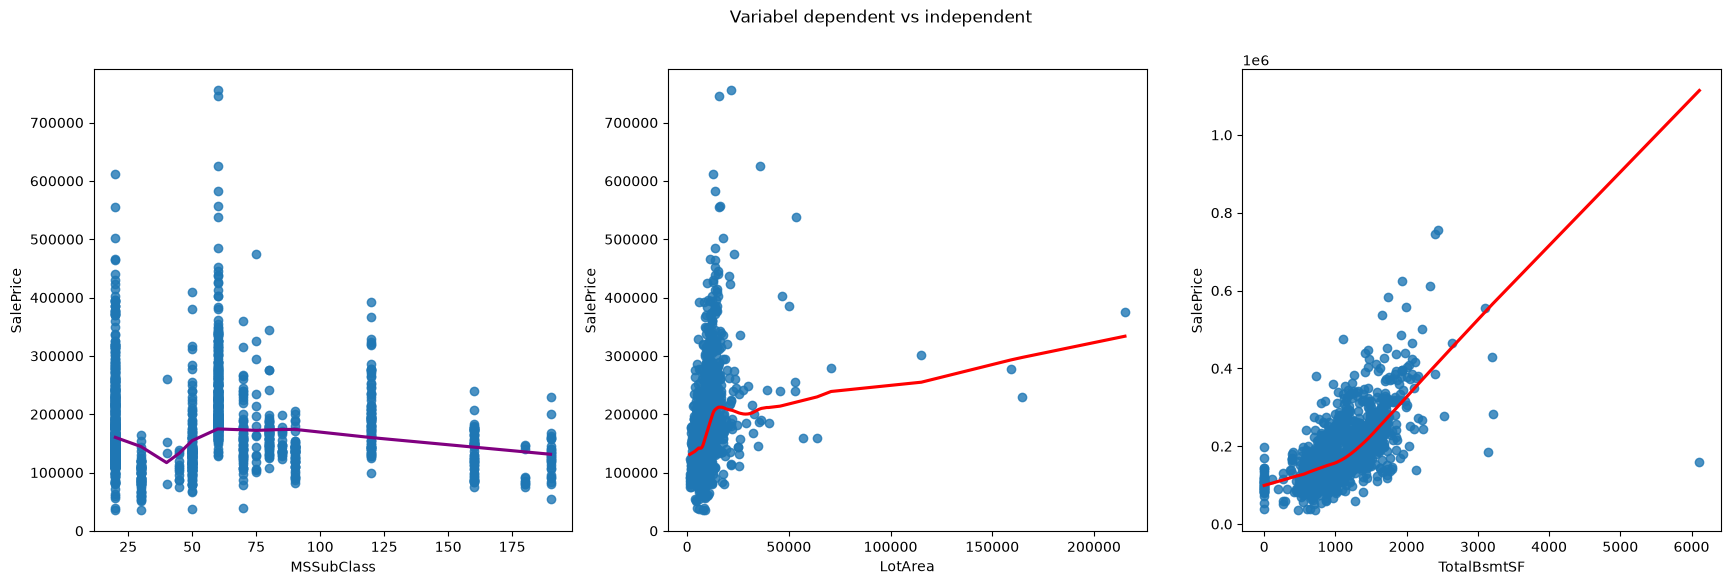

In [22]:
# Uji Linearitas

fig, axes = plt.subplots(1,3, figsize=(21, 6))
fig.suptitle("Variabel dependent vs independent")
sns.regplot(x=house_price['MSSubClass'], y=house_price['SalePrice'], lowess=True, line_kws = {'color':'purple'}, ax=axes[0])
sns.regplot(x=house_price['LotArea'], y=house_price['SalePrice'], lowess=True, line_kws = {'color':'red'}, ax=axes[1])
sns.regplot(x=house_price['TotalBsmtSF'], y=house_price['SalePrice'], lowess=True, line_kws = {'color':'red'}, ax=axes[2])

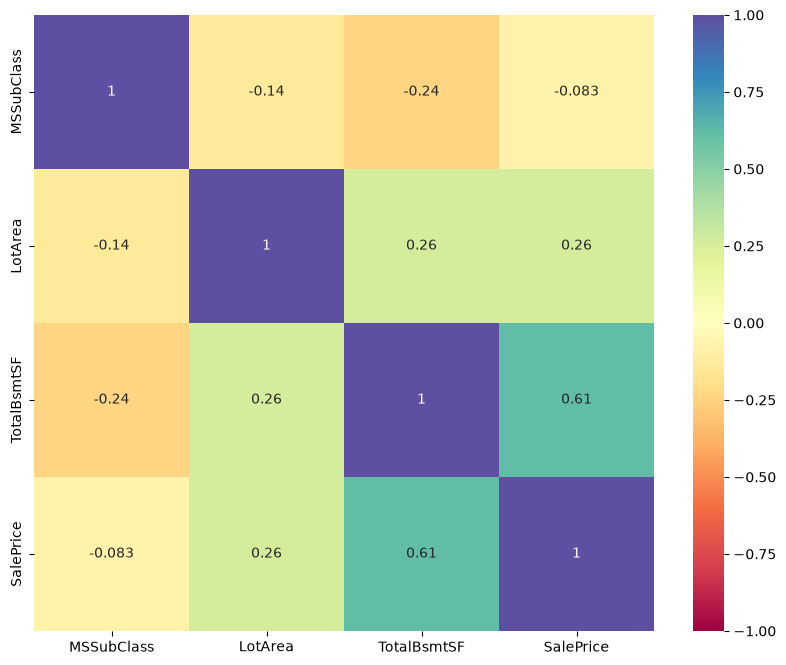

In [25]:
# Uji koeloneritas pake heatmap

plt.figure(figsize=(10,8))
sns.heatmap(house_price.corr(), vmax=1, vmin=-1, center = 0 ,\
    cmap="Spectral", annot=True)
plt.show()

In [26]:
# Scalling data

scaler = StandardScaler()
scaled_house_price = scaler.fit_transform(house_price)
scaled_house_price

array([[ 0.07517373, -0.20766545, -0.45928807,  0.3467638 ],
       [-0.87237242, -0.09242423,  0.4661749 ,  0.00684746],
       [ 0.07517373,  0.07292186, -0.31340228,  0.53560621],
       ...,
       [ 0.31206026, -0.14834127,  0.2154337 ,  1.07695446],
       [-0.87237242, -0.08069969,  0.04675326, -0.48886387],
       [-0.87237242, -0.05865354,  0.4524981 , -0.42119534]],
      shape=(1459, 4))

In [27]:
# ubah ke bentuk dataFrame
scaled_house_price = pd.DataFrame(scaled_house_price, columns=house_price.columns)
scaled_house_price

,MSSubClass,LotArea,TotalBsmtSF,SalePrice
0,0.075174,-0.207665,-0.459288,0.346764
1,-0.872372,-0.092424,0.466175,0.006847
2,0.075174,0.072922,-0.313402,0.535606
3,0.312060,-0.097435,-0.687235,-0.515617
4,0.075174,0.374553,0.199477,0.869228
...,...,...,...,...
1454,0.075174,-0.261077,-0.238180,-0.074984
1455,-0.872372,0.265826,1.104425,0.365648
1456,0.312060,-0.148341,0.215434,1.076954
1457,-0.872372,-0.080700,0.046753,-0.488864


## BUAT MODEL

In [ ]:
# pisahin datanya dulu

x = scaled_house_price.drop("SalePrice", axis=1).values
y = scaled_house_price['SalePrice'].values.reshape(-1,1)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)

In [ ]:
# Cek ukuran dulu

print("Ukuran X train", len(x_train))
print("Ukuran X tes", len(x_test))
print("Ukuran y train", len(y_train))
print("Ukuran y tes", len(y_test))


$$Y=\beta_0+\beta_1X_1+\beta_2X_2+\beta_3X_3+\epsilon$$

In [31]:
input = sm.add_constant(x_train)

In [33]:
# model OLS
SimpleModel = sm.OLS(y_train, input, missing = 'drop')
results = SimpleModel.fit() 

In [34]:
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.436
Model:                            OLS   Adj. R-squared:                  0.435
Method:                 Least Squares   F-statistic:                     262.5
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          3.83e-126
Time:                        16:14:49   Log-Likelihood:                -1131.3
No. Observations:                1021   AIC:                             2271.
Df Residuals:                    1017   BIC:                             2290.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0295      0.023     -1.283      0.2

In [35]:
input_test = sm.add_constant(x_test)
predication_1 = results.predict(input_test)

list_columns = []
for i in house_price.columns:
    if i !="SalePrice":
        list_columns.append(i)
list_columns

df_statmod = pd.DataFrame(x_test, columns=list_columns)
df_statmod['actual_price'] = y_test
df_statmod["predicition_price"] = predication_1
df_statmod.head()


,MSSubClass,LotArea,TotalBsmtSF,actual_price,predicition_price
0,0.075174,0.118016,-0.796649,-0.013296,-0.528878
1,-0.635486,-0.264885,-0.769295,-1.838772,-0.620894
2,0.785833,-0.332928,-2.410510,-1.145091,-1.584237
3,0.785833,0.258410,1.528406,-0.482884,1.070312
4,-0.872372,0.172430,0.972216,-0.074984,0.555958


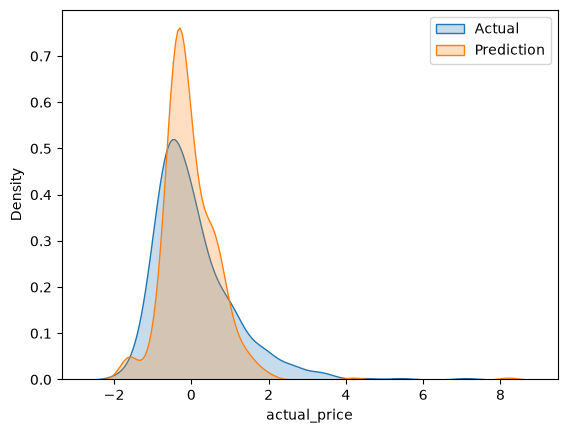

In [36]:
sns.kdeplot(df_statmod['actual_price'], label='Actual', fill = True)
sns.kdeplot(df_statmod['predicition_price'], label='Prediction', fill=True)

plt.legend()
plt.show()

$$MSE (Mean Square Error): \frac{1}{n}\sum_i(y_i -\hat{y}_i)^2$$

$$ ΜΑΕ (Mean Absolut Error): \frac{1}{n}\sum_i y_i\hat{y}_1|$$

$$ RMSE = \sqrt{MSE}$$

In [37]:
# Hitung Evaluasi
print("R-Square: ", metrics.r2_score(df_statmod['actual_price'],
                                     df_statmod['predicition_price']))

R-Square:  0.2905394428318363


In [ ]:
# Hitung Evaluasi
print("MAE: ", metrics.mean_squared_error(df_statmod['actual_price'],
                                     df_statmod['predicition_price']))

MSE:  0.7822772785532602


In [ ]:
# Hitung Evaluasi
print("MSE: ", metrics.mean_absolute_error(df_statmod['actual_price'],
                                     df_statmod['predicition_price']))

MAE:  0.588761298019237
